# Sector Means and Medians of the Topic Relevance Score Relative to the Sample

| Item | Description |
|---|---|
| Goal | Two figures for the topic relevance score of T3.4.1: one horizontal bar per NAICS two-digit sector, showing the sector mean minus the sample mean and, separately, the sector median minus the sample median, with nested 90, 95, and 99 percent intervals. Zero is the sample statistic. |
| Input | `firm_relevance.parquet` from T3.4.1 in the T3.4 Processed folder. |
| Output | Under `R - Results/tables/...`: `table_naics2_sector_means_and_medians.csv`, one row per sector with the number of firms, the mean, the median, their differences from the sample statistic, and the interval bounds. Under `R - Results/figures/...`: `fig_sector_<mean\|median>_minus_sample_<mean\|median>_policy_summary_firm_summary_cosine_naics2`, two figures as PNG, SVG, and PDF. |
| Groups | The firm's Compustat NAICS code cut to two digits, as in T3.4.1. Sectors with fewer than `min_firms` firms are left out of the figures and named in the Notes. |
| Intervals | For the mean, two-sided normal confidence intervals from the standard deviation of the firm scores within the group. For the median, percentile bootstrap intervals from 5,000 resamples of the group's firms. All nested, drawn without caps, the thickest line for 90 percent. |
| Style | S3: GREY bars, DODGER_BLUE intervals, a BLACK zero line, no legend, no text inside the plot, title and notes in Markdown below. Tick labels carry the sector name, its NAICS codes, and its number of firms, in title case as in the proposal. |
| Run | Run 2026-11-01. The mean figure is Figure 3, Panel A of the proposal; the three-digit subsector figures of the earlier version are dropped. |


## Step 1. Import packages


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display


## Step 2. Define file locations, the sample, the group names, the statistics, and the wording


In [2]:
PROJECT_FOLDER = Path.cwd().resolve().parents[2]  # <pipeline>/<section>/<subfolder>/ sits three levels below the clone
SCRATCH_FOLDER = Path("/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis")  # the one line to change on another machine
NOTEBOOK_SUBFOLDER = Path("T - Three Step Text Analysis Pipeline/T3 - Topic Relevance and Corporate Disclosure/T3.4 - Topic Relevance - Score and Figures")
NOTEBOOK_NAME = "T3.4.3 - Figure - Sector Means and Medians"  # the notebook filename without .ipynb
RAW_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Raw"
INTERIM_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Interim"
PROCESSED_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Processed"
SCORES_FILE = PROCESSED_FOLDER / "firm_relevance.parquet"

SAMPLE = "all_years"  # the main sample; "three_years" for the three-year figures
CONFIDENCE_LEVELS = [90, 95, 99]  # nested intervals; the wider the interval, the thinner its line
Z_VALUES = {90: 1.645, 95: 1.960, 99: 2.576}  # two-sided normal critical values for the mean
N_BOOTSTRAP = 5000  # resamples of each group's firms for the median's intervals
BOOTSTRAP_SEED = 0
NAICS_SECTORS = {  # two-digit code -> sector name; codes that share a sector map to the same name
    "11": "Agriculture, forestry, fishing and hunting", "21": "Mining, quarrying, and oil and gas extraction", "22": "Utilities", "23": "Construction",
    "31": "Manufacturing", "32": "Manufacturing", "33": "Manufacturing", "42": "Wholesale trade", "44": "Retail trade", "45": "Retail trade",
    "48": "Transportation and warehousing", "49": "Transportation and warehousing", "51": "Information", "52": "Finance and insurance",
    "53": "Real estate and rental and leasing", "54": "Professional, scientific, and technical services", "55": "Management of companies and enterprises",
    "56": "Administrative and support and waste management", "61": "Educational services", "62": "Health care and social assistance",
    "71": "Arts, entertainment, and recreation", "72": "Accommodation and food services", "81": "Other services", "92": "Public administration",
    "99": "Unclassified",
}
LOWERCASE_WORDS = {"a", "an", "the", "and", "or", "but", "of", "in", "on", "at", "to", "for", "by", "except"}  # kept lowercase in title case
SECTOR_TITLES = {name: " ".join(word if word in LOWERCASE_WORDS and i > 0 else word[0].upper() + word[1:] for i, word in enumerate(name.split(" "))) for name in set(NAICS_SECTORS.values())}
SECTOR_CODES = {}  # sector name -> "51" or "31 to 33"
for code_, name in NAICS_SECTORS.items():
    codes = sorted(c for c, n in NAICS_SECTORS.items() if n == name)
    SECTOR_CODES[name] = codes[0] if len(codes) == 1 else f"{codes[0]} to {codes[-1]}"
LEVELS = {
    "naics2": {"column": "sector", "min_firms": 5, "group": "Sector", "level_title": "NAICS Two-Digit Sector", "y_title": "NAICS Two-Digit Sector (NAICS Codes, Number of Firms)", "tick_lines": 2, "tick_size": 9},
}
STATISTICS = {"mean": "Mean", "median": "Median"}
FIRM_SUMMARY_TITLE = "a Firm-Level Summary of 10-K Item 1s"
POLICY_SUMMARY_TITLE = "the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation"
SCORE_TITLE = f"Cosine Similarity Between {FIRM_SUMMARY_TITLE} and {POLICY_SUMMARY_TITLE}"
SCORE_WORDS = ("the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's "
               "yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the "
               "language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. "
               "A higher score means that the firm's business description is closer to the policy summary")
SAMPLE_WORDS = {"three_years": "the three-year sample (fiscal years 2010, 2015, and 2020)", "all_years": "the all-years sample (every fiscal year a firm filed, 1999 to 2025)"}
SOURCE = "10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations"
FIGURE_FOLDER = PROJECT_FOLDER / "R - Results/figures" / NOTEBOOK_SUBFOLDER / NOTEBOOK_NAME
TABLE_FOLDER = PROJECT_FOLDER / "R - Results/tables" / NOTEBOOK_SUBFOLDER / NOTEBOOK_NAME
MODEL_CACHE = SCRATCH_FOLDER / "cache" / "huggingface"
ENV_FILE = PROJECT_FOLDER / "T - Three Step Text Analysis Pipeline/T3 - Topic Relevance and Corporate Disclosure" / ".env"
for folder in (FIGURE_FOLDER, TABLE_FOLDER):
    folder.mkdir(parents=True, exist_ok=True)


## Step 3. Apply the figure style


In [3]:
# Colors from the Figure Style Guide
BLACK = "#000000"
DODGER_BLUE = "#1E90FF"
SLATE_GREY = "#708090"
CYAN = "#00ACC1"
GREY = "#A6A6A8"

# Font and background
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (9, 6)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True

# Horizontal background lines only
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5

# All text and axis lines in BLACK
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK

FIGURE_WIDTH, FIGURE_HEIGHT = 9, 6
MARGIN_INCHES = 0.5 / 2.54  # 0.5 cm between each edge of the image and the nearest element
ZERO_LINE_WIDTH = 0.8 / 3
EXPORT_DPI = 300
BAR_HEIGHT = 0.7
INTERVAL_WIDTHS = {90: 3.2, 95: 1.8, 99: 0.8}  # line widths of the nested intervals, thickest for the narrowest


def fit_margins(figure, axis):
    """Move the axes so the Y-title starts 0.5 cm from the left edge, the X-title ends 0.5 cm above the bottom edge, and nothing crosses the right or top margin."""
    figure.canvas.draw()
    renderer = figure.canvas.get_renderer()
    margin = MARGIN_INCHES * figure.dpi
    left_shift = (margin - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
    figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
    figure.canvas.draw()
    bottom_shift = (margin - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
    figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
    figure.canvas.draw()
    box = axis.get_tightbbox(renderer)
    right_over = box.x1 - (figure.bbox.width - margin)
    top_over = box.y1 - (figure.bbox.height - margin)
    if right_over > 0 or top_over > 0:
        figure.subplots_adjust(right=figure.subplotpars.right - max(right_over, 0) / figure.bbox.width,
                               top=figure.subplotpars.top - max(top_over, 0) / figure.bbox.height)
        figure.canvas.draw()
    return renderer


def legend_below(figure, axis, handles, labels, ncol=1, fontsize=10):
    """Place the legend with its top 0.5 cm below the X-title and its bottom 0.5 cm above the bottom edge; the bottom margin grows to make room."""
    renderer = fit_margins(figure, axis)
    margin = MARGIN_INCHES * figure.dpi
    axis_box = axis.get_window_extent(renderer)
    center = (axis_box.x0 + axis_box.x1) / 2 / figure.bbox.width
    x_title = axis.xaxis.label.get_window_extent(renderer)
    legend = figure.legend(handles, labels, loc="upper center", bbox_to_anchor=(center, (x_title.y0 - margin) / figure.bbox.height),
                           bbox_transform=figure.transFigure, ncol=ncol, frameon=False, handlelength=1.6, fontsize=fontsize)
    figure.canvas.draw()
    bottom_shift = (margin - legend.get_window_extent(renderer).y0) / figure.bbox.height
    figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
    figure.canvas.draw()
    x_title = axis.xaxis.label.get_window_extent(renderer)
    legend.set_bbox_to_anchor((center, (x_title.y0 - margin) / figure.bbox.height), transform=figure.transFigure)
    figure.canvas.draw()
    return legend


def save_figure(figure, stem):
    """Export PNG, SVG, and PDF into the notebook's figure folder."""
    FIGURE_FOLDER.mkdir(parents=True, exist_ok=True)
    for extension in ("png", "svg", "pdf"):
        figure.savefig(FIGURE_FOLDER / f"{stem}.{extension}", dpi=EXPORT_DPI if extension == "png" else None)
    plt.close(figure)
    print(f"saved {stem}.png/.svg/.pdf")


def show_figure(number, title, stem, notes, source):
    """Title, image, Notes, and Source, in that order, as Markdown outside the image."""
    display(Markdown(f"**Figure {number}. {title}**"))
    display(Image(filename=str(FIGURE_FOLDER / f"{stem}.png"), width=900))
    display(Markdown(f"*Notes*: {notes}"))
    display(Markdown(f"*Source*: {source}."))


## Step 4. Load the scores

The chosen sample only; every firm carries its two-digit sector from T3.4.1.


In [4]:
scores = pd.read_parquet(SCORES_FILE)
scores = scores.loc[scores["sample"].eq(SAMPLE)].reset_index(drop=True)
assert scores["score"].notna().all()
print(f"Firms in the {SAMPLE} sample: {len(scores):,}; two-digit sectors: {scores['sector'].nunique()}")


Firms in the all_years sample: 1,058; two-digit sectors: 19


## Step 5. Compute the group statistics and their intervals

For each sector: the number of firms, the mean with its normal intervals, and the median with its bootstrap intervals. Each is expressed relative to the sample statistic of the same kind. One table, sorted from the highest mean, is saved.


In [5]:
sample_statistic = {"mean": float(scores["score"].mean()), "median": float(scores["score"].median())}
rng = np.random.default_rng(BOOTSTRAP_SEED)
group_tables = {}
for level, settings in LEVELS.items():
    rows = []
    for group, part in scores.groupby(settings["column"]):
        values = part["score"].to_numpy()
        row = {"group": group, "codes": SECTOR_CODES[group] if level == "naics2" else part["naics3"].iloc[0], "n_firms": len(values), "mean": float(values.mean()),
               "sd": float(values.std(ddof=1)) if len(values) > 1 else np.nan, "median": float(np.median(values))}
        row["se"] = row["sd"] / np.sqrt(len(values)) if len(values) > 1 else np.nan
        row["mean_minus_sample_mean"] = row["mean"] - sample_statistic["mean"]
        row["median_minus_sample_median"] = row["median"] - sample_statistic["median"]
        resampled_medians = np.median(rng.choice(values, size=(N_BOOTSTRAP, len(values)), replace=True), axis=1)
        for level_pct in CONFIDENCE_LEVELS:
            row[f"mean_ci{level_pct}_lower"] = row["mean_minus_sample_mean"] - Z_VALUES[level_pct] * row["se"]
            row[f"mean_ci{level_pct}_upper"] = row["mean_minus_sample_mean"] + Z_VALUES[level_pct] * row["se"]
            tail = (100 - level_pct) / 2
            row[f"median_ci{level_pct}_lower"] = float(np.percentile(resampled_medians, tail)) - sample_statistic["median"]
            row[f"median_ci{level_pct}_upper"] = float(np.percentile(resampled_medians, 100 - tail)) - sample_statistic["median"]
        rows.append(row)
    table = pd.DataFrame(rows).sort_values("mean", ascending=False).reset_index(drop=True)
    table.insert(3, "sample_mean", sample_statistic["mean"])
    table.insert(4, "sample_median", sample_statistic["median"])
    group_tables[level] = table
    table.to_csv(TABLE_FOLDER / f"table_{level}_{settings['column']}_means_and_medians.csv", index=False, float_format="%.6f")
    print(f"{settings['group']}s: {len(table)}; {int(table['n_firms'].ge(settings['min_firms']).sum())} with at least {settings['min_firms']} firms are drawn")
print(f"Sample mean {sample_statistic['mean']:.4f}, sample median {sample_statistic['median']:.4f} over all {len(scores):,} firms; {N_BOOTSTRAP:,} bootstrap resamples per group")
display(group_tables["naics2"][["group", "codes", "n_firms", "mean", "mean_minus_sample_mean", "mean_ci90_lower", "mean_ci90_upper", "median", "median_minus_sample_median"]].round(4))


Sectors: 19; 15 with at least 5 firms are drawn
Sample mean 0.5121, sample median 0.5106 over all 1,058 firms; 5,000 bootstrap resamples per group


,group,codes,n_firms,mean,mean_minus_sample_mean,mean_ci90_lower,mean_ci90_upper,median,median_minus_sample_median
0,Information,51,113,0.5466,0.0345,0.0296,0.0394,0.5463,0.0357
1,Unclassified,99,4,0.5420,0.0299,0.0225,0.0373,0.5462,0.0356
2,"Professional, scientific, and technical services",54,38,0.5348,0.0227,0.0125,0.0328,0.5362,0.0257
3,Administrative and support and waste management,56,14,0.5265,0.0144,-0.0022,0.0310,0.5177,0.0071
4,Health care and social assistance,62,13,0.5232,0.0111,-0.0029,0.0250,0.5273,0.0168
5,Retail trade,44 to 45,59,0.5157,0.0036,-0.0037,0.0109,0.5217,0.0111
6,Other services,81,3,0.5141,0.0020,-0.0027,0.0067,0.5138,0.0032
7,Manufacturing,31 to 33,420,0.5106,-0.0015,-0.0041,0.0011,0.5079,-0.0027
8,"Agriculture, forestry, fishing and hunting",11,3,0.5092,-0.0029,-0.0384,0.0326,0.5180,0.0074
9,Construction,23,11,0.5087,-0.0034,-0.0161,0.0093,0.5024,-0.0082


## Step 6. Draw the two figures

For each statistic: sectors with enough firms, the highest at the top. Each GREY bar runs from zero to the group statistic minus the sample statistic; the DODGER_BLUE lines span the nested intervals; a BLACK line marks zero.


In [6]:
figure_records = []
figure_number = 0
for level, settings in LEVELS.items():
    group_word = settings["group"]
    for statistic, statistic_word in STATISTICS.items():
        figure_number += 1
        table = group_tables[level].sort_values(statistic, ascending=False).reset_index(drop=True)
        plotted = table.loc[table["n_firms"].ge(settings["min_firms"])].reset_index(drop=True)
        left_out = table.loc[table["n_firms"].lt(settings["min_firms"])]
        difference = f"{statistic}_minus_sample_{statistic}"
        figure_name = f"fig_{group_word.lower()}_{statistic}_minus_sample_{statistic}_policy_summary_firm_summary_cosine_{level}"
        title = f"{group_word} {statistic_word} Minus Sample {statistic_word} of {SCORE_TITLE}, by {settings['level_title']}"
        x_title = (f"{group_word} {statistic_word} Minus Sample {statistic_word} of Cosine Similarity Between\na Firm-Level Summary of 10-K Item 1s and the Policy Summary\n"
                   "of Legislator Statements on Consumer Data Privacy Legislation")
        names = [SECTOR_TITLES[g] for g in plotted["group"]] if level == "naics2" else plotted["group"].tolist()
        if settings["tick_lines"] == 2:
            labels = [f"{name}\n(NAICS {codes}, {n:,} Firms)" for name, codes, n in zip(names, plotted["codes"], plotted["n_firms"])]
        else:
            labels = [f"{name} ({codes}, {n:,} Firms)" for name, codes, n in zip(names, plotted["codes"], plotted["n_firms"])]
        positions = np.arange(len(plotted))[::-1]
        reach = float(max(plotted[f"{statistic}_ci99_lower"].abs().max(), plotted[f"{statistic}_ci99_upper"].abs().max(), plotted[difference].abs().max())) * 1.05

        figure, axis = plt.subplots()
        figure.subplots_adjust(left=0.4, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.18)
        axis.barh(positions, plotted[difference], color=GREY, height=BAR_HEIGHT, zorder=2)
        for order, level_pct in enumerate(sorted(CONFIDENCE_LEVELS, reverse=True), start=3):
            below = np.clip(plotted[difference] - plotted[f"{statistic}_ci{level_pct}_lower"], 0, None)
            above = np.clip(plotted[f"{statistic}_ci{level_pct}_upper"] - plotted[difference], 0, None)
            axis.errorbar(plotted[difference], positions, xerr=np.vstack([below, above]), fmt="none", ecolor=DODGER_BLUE, elinewidth=INTERVAL_WIDTHS[level_pct], capsize=0, zorder=order)
        axis.axvline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=3 + len(CONFIDENCE_LEVELS))
        axis.set_yticks(positions, labels=labels)
        axis.set_ylim(positions.min() - 0.6, positions.max() + 0.6)
        axis.set_xlim(-reach, reach)
        axis.set_xlabel(x_title)
        axis.set_ylabel(settings["y_title"])
        axis.tick_params(axis="y", length=0, labelsize=settings["tick_size"])
        axis.spines[["top", "right"]].set_visible(False)
        renderer = fit_margins(figure, axis)
        x_title_box = axis.xaxis.label.get_window_extent(renderer)
        assert x_title_box.x0 >= MARGIN_INCHES * figure.dpi - 1 and x_title_box.x1 <= figure.bbox.width - MARGIN_INCHES * figure.dpi + 1, "the X-title crosses a side margin"
        save_figure(figure, figure_name)

        if statistic == "mean":
            interval_words = (f"The three nested lines span the 90, 95, and 99 percent confidence intervals of the {group_word.lower()} mean, the thickest line the 90 percent and the thinnest "
                              f"the 99 percent, {Z_VALUES[90]}, {Z_VALUES[95]}, and {Z_VALUES[99]} standard errors on each side, where the standard error is the standard deviation of the "
                              f"firm scores within the {group_word.lower()} divided by the square root of the number of firms")
        else:
            interval_words = (f"The three nested lines span the 90, 95, and 99 percent percentile bootstrap intervals of the {group_word.lower()} median, the thickest line the 90 percent "
                              f"and the thinnest the 99 percent: the {group_word.lower()}'s firms are resampled with replacement {N_BOOTSTRAP:,} times, the median is taken each time, and "
                              "each interval is the central 90, 95, or 99 percent of those medians, so an interval can be asymmetric around the bar end")
        left_out_words = (f" {group_word}s with fewer than {settings['min_firms']} firms are left out: " + "; ".join(
            f"{(SECTOR_TITLES[g] if level == 'naics2' else g)} (NAICS {c}, {int(n)} firms)" for g, c, n in zip(left_out['group'], left_out['codes'], left_out['n_firms'])) + ".") if len(left_out) else ""
        grouping = ("two digits, with codes 31 to 33 merged into manufacturing, 44 to 45 into retail trade, and 48 to 49 into transportation and warehousing" if level == "naics2"
                    else "three digits, named by NAICS 2022 where the code exists in that vintage and by the older vintage otherwise")
        notes = (f"Each bar is the {group_word.lower()} {statistic} minus the sample {statistic} of the firm score, the {statistic} over all {len(scores):,} firms of {SAMPLE_WORDS[SAMPLE]}, "
                 f"{sample_statistic[statistic]:.3f}: zero is the sample {statistic}, a bar to the right is a {group_word.lower()} above it and a bar to the left a {group_word.lower()} below it, "
                 f"and {group_word.lower()}s are ordered from the highest {statistic} at the top to the lowest at the bottom. The score is {SCORE_WORDS}. {interval_words}; an interval that "
                 f"does not cross zero marks a {group_word.lower()} whose {statistic} differs from the sample {statistic} at that confidence level. The {group_word.lower()} is the firm's "
                 f"Compustat NAICS code cut to {grouping}; each tick label gives the code{'s' if level == 'naics2' else ''} and the number of firms.{left_out_words}")
        figure_records.append((figure_number, figure_name, title, notes))
        print(f"Figure {figure_number}: {figure_name} ({len(plotted)} {group_word.lower()}s)")


saved fig_sector_mean_minus_sample_mean_policy_summary_firm_summary_cosine_naics2.png/.svg/.pdf
Figure 1: fig_sector_mean_minus_sample_mean_policy_summary_firm_summary_cosine_naics2 (15 sectors)


saved fig_sector_median_minus_sample_median_policy_summary_firm_summary_cosine_naics2.png/.svg/.pdf
Figure 2: fig_sector_median_minus_sample_median_policy_summary_firm_summary_cosine_naics2 (15 sectors)


## Step 7. Show the figures

Title, image, Notes, and Source for each figure: the mean, then the median.


**Figure 1. Sector Mean Minus Sample Mean of Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation, by NAICS Two-Digit Sector**

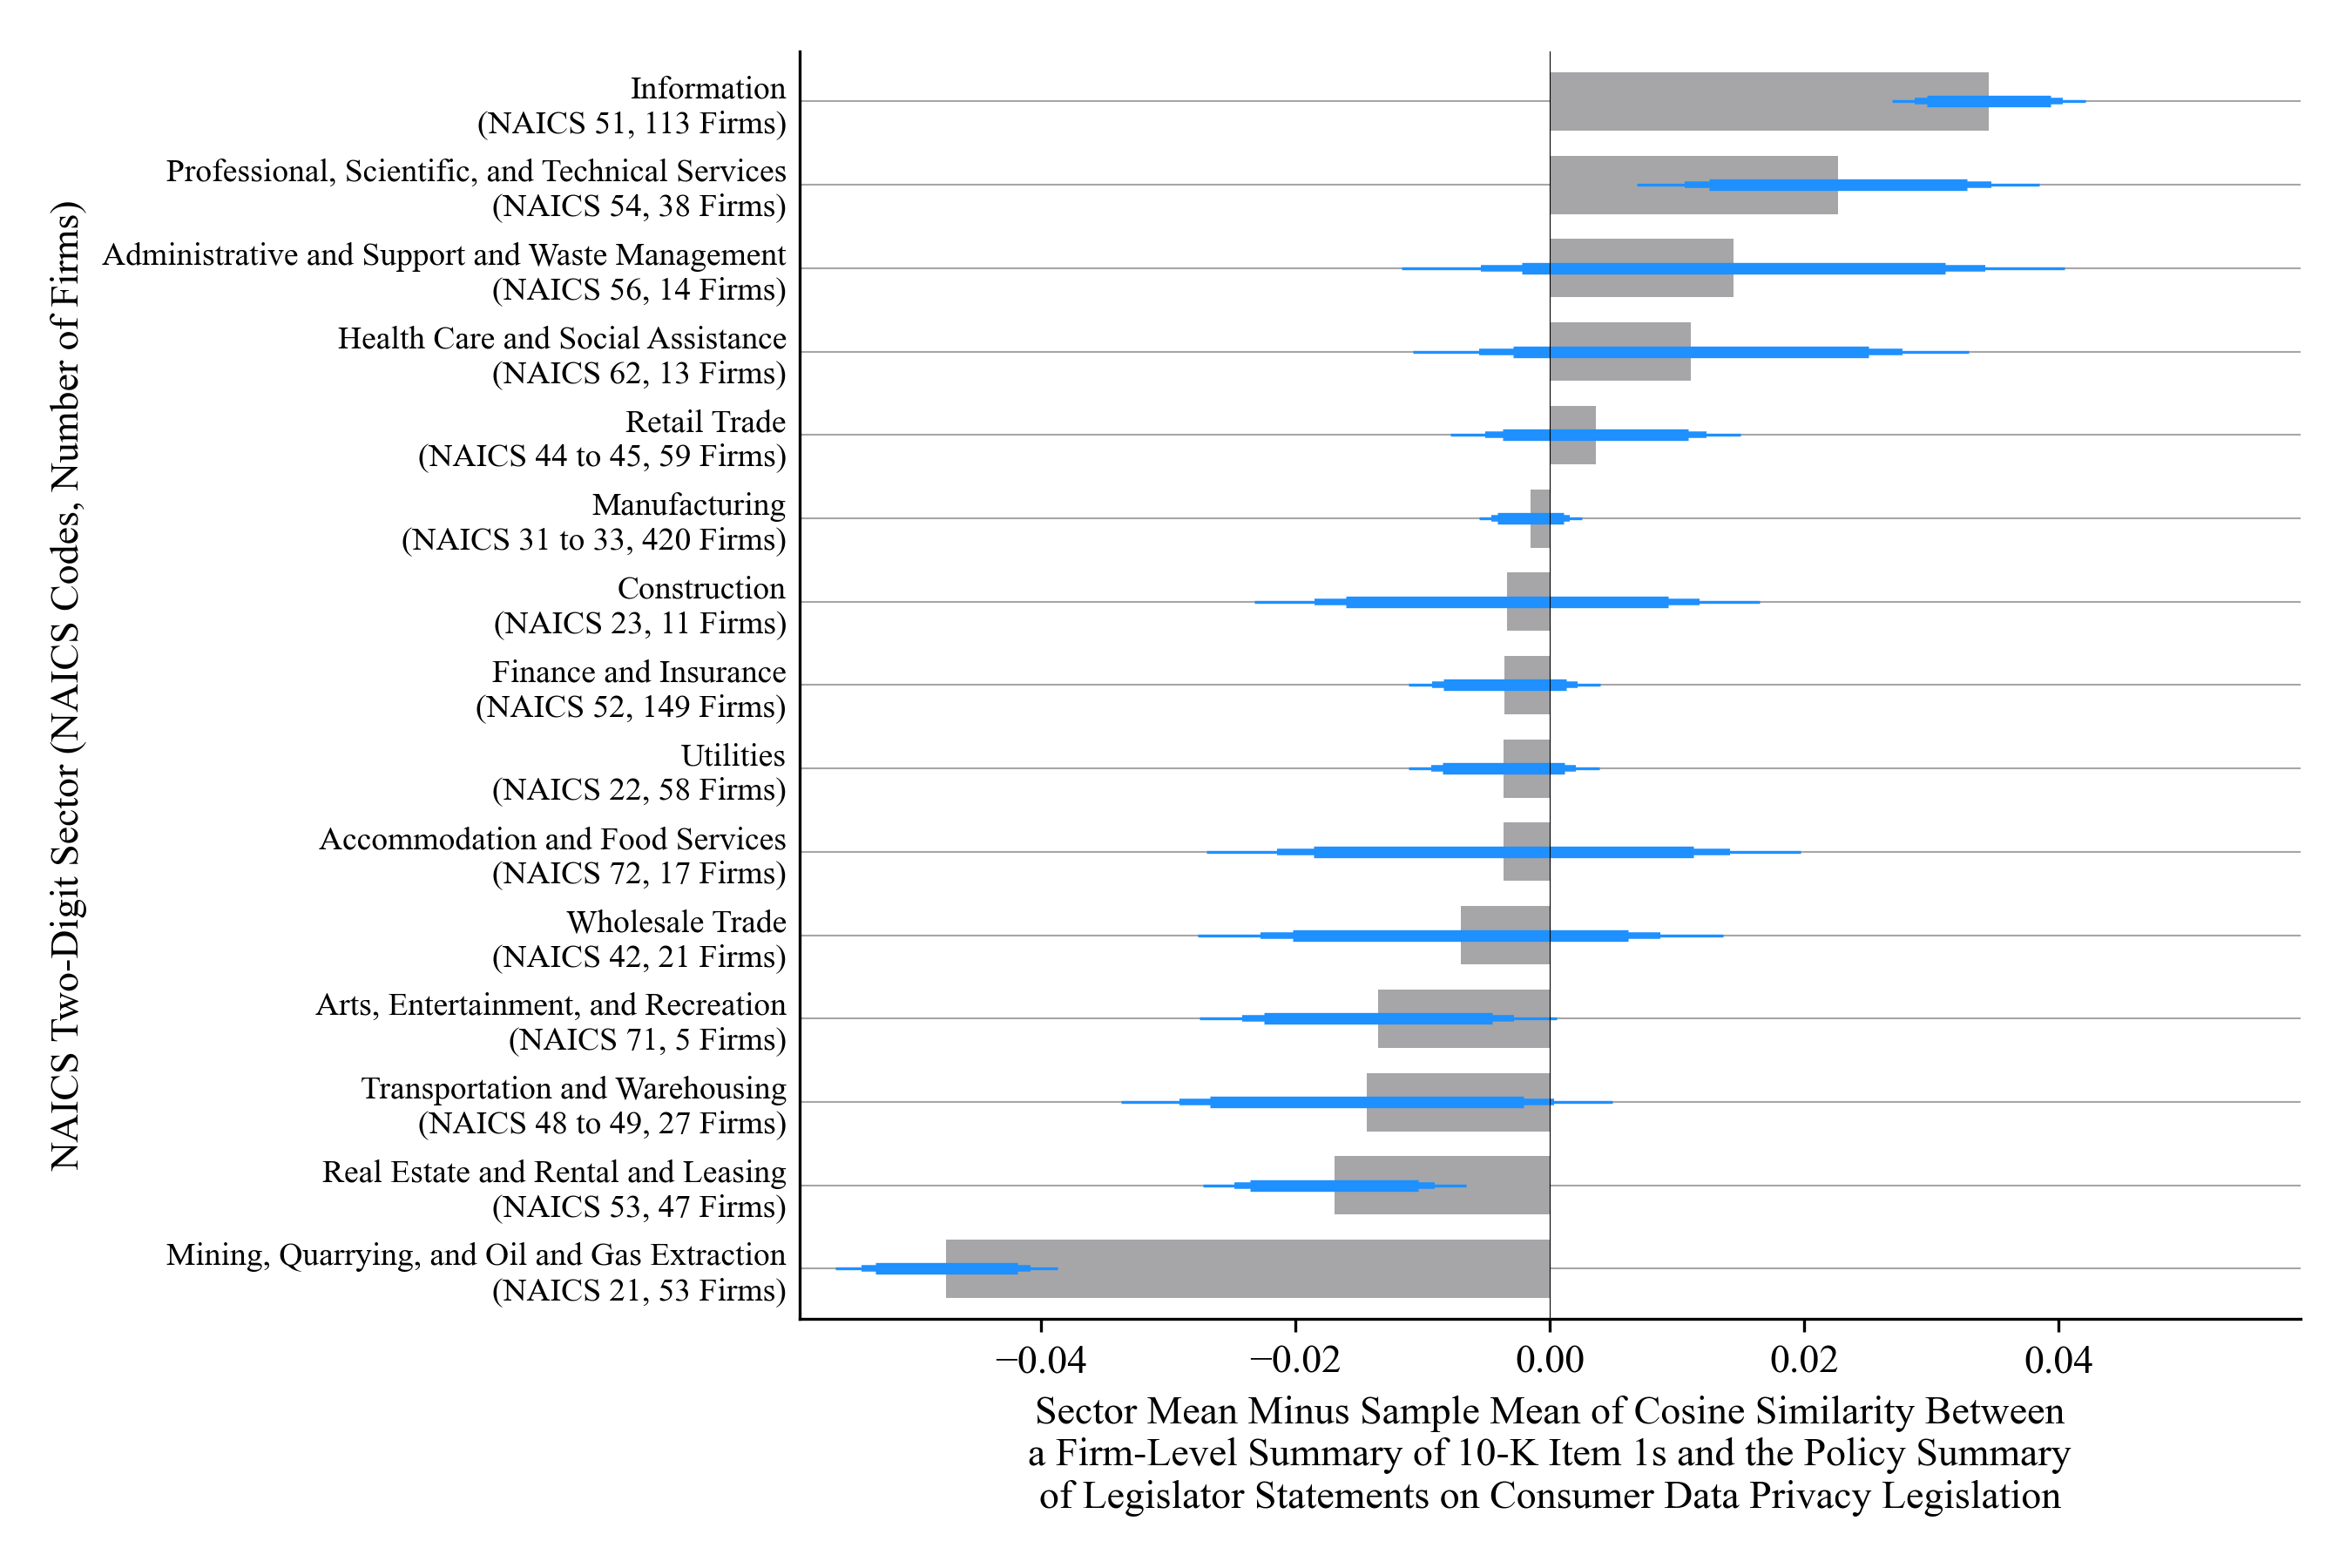

*Notes*: Each bar is the sector mean minus the sample mean of the firm score, the mean over all 1,058 firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025), 0.512: zero is the sample mean, a bar to the right is a sector above it and a bar to the left a sector below it, and sectors are ordered from the highest mean at the top to the lowest at the bottom. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. The three nested lines span the 90, 95, and 99 percent confidence intervals of the sector mean, the thickest line the 90 percent and the thinnest the 99 percent, 1.645, 1.96, and 2.576 standard errors on each side, where the standard error is the standard deviation of the firm scores within the sector divided by the square root of the number of firms; an interval that does not cross zero marks a sector whose mean differs from the sample mean at that confidence level. The sector is the firm's Compustat NAICS code cut to two digits, with codes 31 to 33 merged into manufacturing, 44 to 45 into retail trade, and 48 to 49 into transportation and warehousing; each tick label gives the codes and the number of firms. Sectors with fewer than 5 firms are left out: Unclassified (NAICS 99, 4 firms); Other Services (NAICS 81, 3 firms); Agriculture, Forestry, Fishing and Hunting (NAICS 11, 3 firms); Educational Services (NAICS 61, 3 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

**Figure 2. Sector Median Minus Sample Median of Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation, by NAICS Two-Digit Sector**

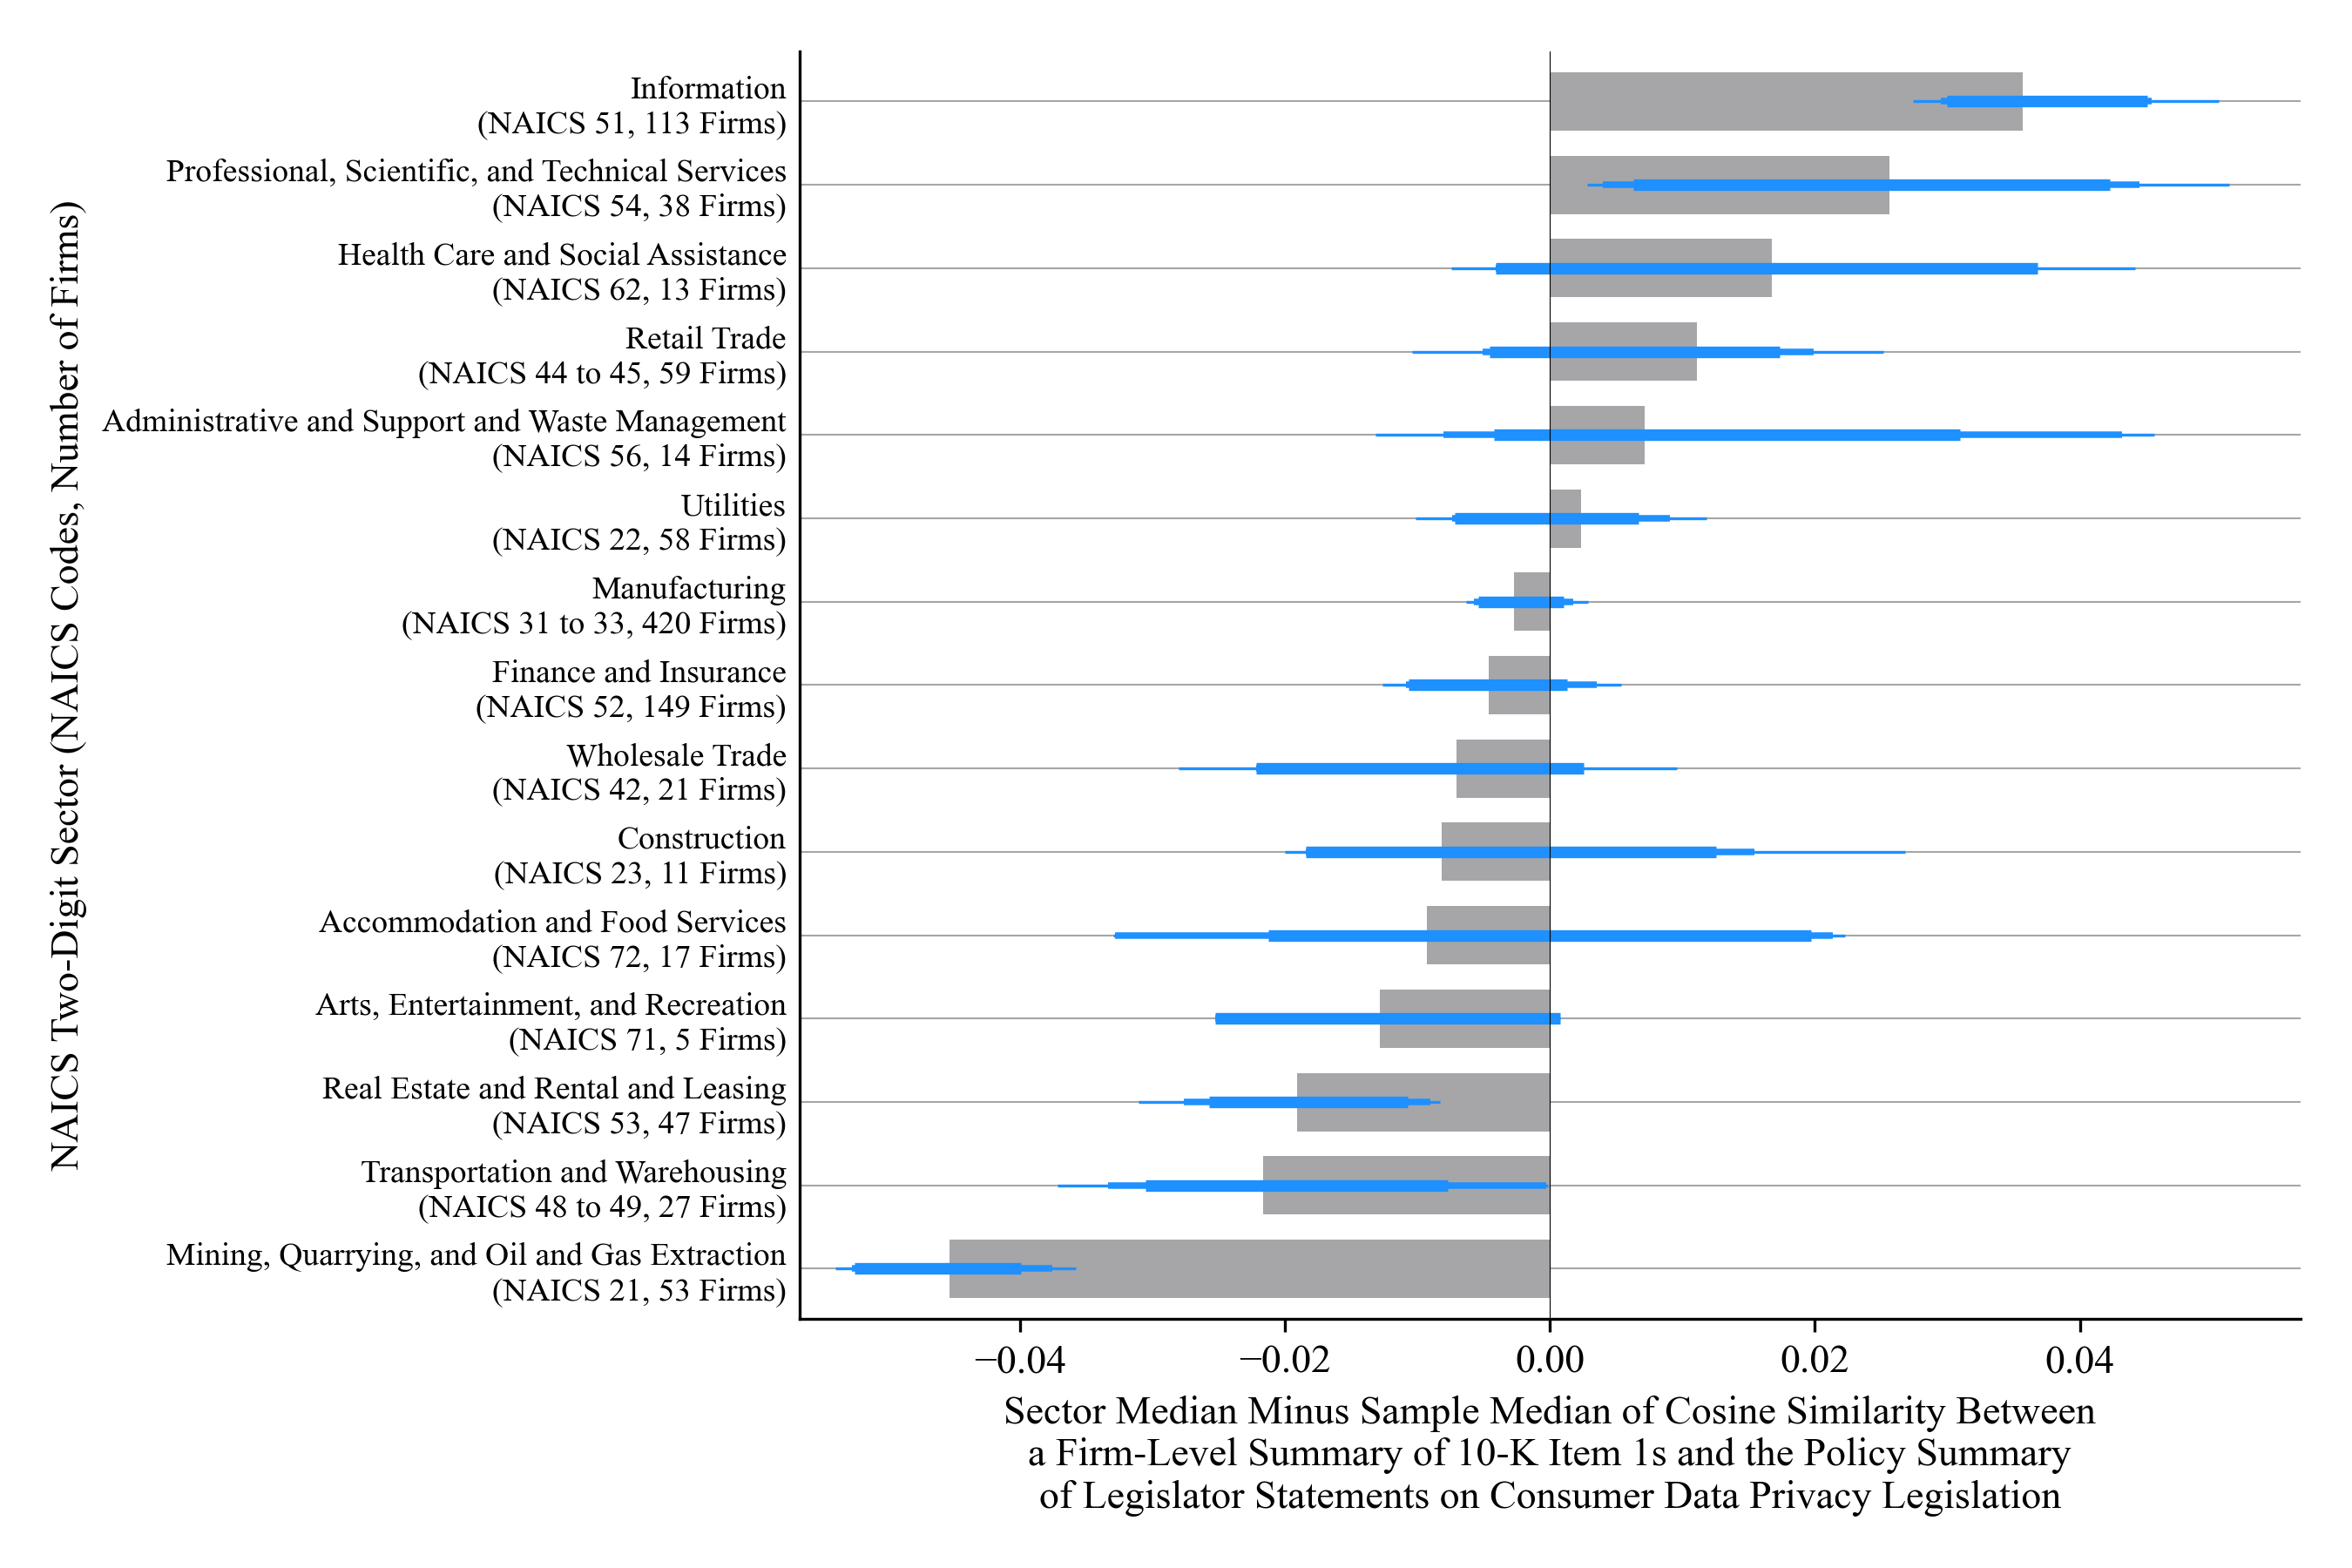

*Notes*: Each bar is the sector median minus the sample median of the firm score, the median over all 1,058 firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025), 0.511: zero is the sample median, a bar to the right is a sector above it and a bar to the left a sector below it, and sectors are ordered from the highest median at the top to the lowest at the bottom. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. The three nested lines span the 90, 95, and 99 percent percentile bootstrap intervals of the sector median, the thickest line the 90 percent and the thinnest the 99 percent: the sector's firms are resampled with replacement 5,000 times, the median is taken each time, and each interval is the central 90, 95, or 99 percent of those medians, so an interval can be asymmetric around the bar end; an interval that does not cross zero marks a sector whose median differs from the sample median at that confidence level. The sector is the firm's Compustat NAICS code cut to two digits, with codes 31 to 33 merged into manufacturing, 44 to 45 into retail trade, and 48 to 49 into transportation and warehousing; each tick label gives the codes and the number of firms. Sectors with fewer than 5 firms are left out: Unclassified (NAICS 99, 4 firms); Agriculture, Forestry, Fishing and Hunting (NAICS 11, 3 firms); Other Services (NAICS 81, 3 firms); Educational Services (NAICS 61, 3 firms).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [7]:
for figure_number, figure_name, title, notes in figure_records:
    show_figure(figure_number, title, figure_name, notes, SOURCE)
